In [30]:
import numpy as np
from numpy.polynomial.legendre import leggauss as PLG
from scipy.integrate import quad
import math
import scipy.special as sp
import matplotlib.pyplot as plt

In [ ]:


## pour des polynomes de dégre differents 
def p1(x):
    return x 
def p2(x):
    return x**2
def p3(x):
    return x**3
def p4(x): 
    return x**4
def p9(x):
    return x**9
def p5(x):
    return x**5
def p6(x):
    return x**6
    
def p10(x):
    return x**10
def p7(x):
    return x**7
def p8(x):
    return x**8

def Gauss_legendre2(f,W,X):

    XX = np.array(X)
    WW = np.array(W)
    return np.sum(WW*f(XX))
    
## on teste pour 2 pooints 

W =[1,1]
X = [-1/np.sqrt(3) , 1/np.sqrt(3)]


#Gauss_legendre2(p4,W,X)


erreur1 = float(quad(p4,-1,1)[0]-Gauss_legendre2(p4,W,X))
#print(f"erreur1 = {erreur1}")
## On remarque que cette formule est vrai pour des polynome de dégré inférieur ou égal à 3 


## Fonction qui approche l'intégrale sur [a,b] de f avec une quadrature de Gauss Legendre à n points
def Gauss_legendre(f,n,a,b):
    # Noeuds et poids sur [-1,1]
    X,W = PLG(n) 
    X,W = np.array(X),np.array(W) 

    # Nouveau noeuds et poids sur [a,b]

    X = (b - a)/2*X + (b + a)/2
    W = (b - a)/2*W

    result = np.sum(W*f(X))

    error = np.abs(quad(f,a,b)[0] - result)

    print(f" ExactSol = {quad(f,a,b)[0]:.6f}")
    print(f" Approx_sol = { result:.6f}")
    print(f" Error = {error:.6f}") 

    return 


In [4]:
for k in range(11):
    p = lambda x: x**k 
    Gauss_legendre(p,5,-1,1) 
    #print("  ")
    

    

 ExactSol = 2.000000
 Approx_sol = 2.000000
 Error = 0.000000
 ExactSol = 0.000000
 Approx_sol = 0.000000
 Error = 0.000000
 ExactSol = 0.666667
 Approx_sol = 0.666667
 Error = 0.000000
 ExactSol = 0.000000
 Approx_sol = 0.000000
 Error = 0.000000
 ExactSol = 0.400000
 Approx_sol = 0.400000
 Error = 0.000000
 ExactSol = 0.000000
 Approx_sol = 0.000000
 Error = 0.000000
 ExactSol = 0.285714
 Approx_sol = 0.285714
 Error = 0.000000
 ExactSol = 0.000000
 Approx_sol = 0.000000
 Error = 0.000000
 ExactSol = 0.222222
 Approx_sol = 0.222222
 Error = 0.000000
 ExactSol = 0.000000
 Approx_sol = 0.000000
 Error = 0.000000
 ExactSol = 0.181818
 Approx_sol = 0.178886
 Error = 0.002932


In [15]:
X,W = PLG(5)
print(X)

[-0.90617985 -0.53846931  0.          0.53846931  0.90617985]


 Erreur_relative  = 0.012343990885176313:


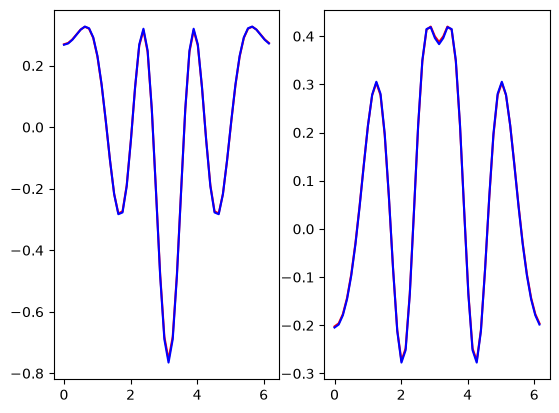

In [67]:
## 3)  On code la representation intégrale sous forme de produit matrice-vecteur

## données du probème 

a = 5.0            # rayon du disque
k = 1.0            # nombre d'onde
Nbre_elmt,Nbre_noeud = 50,50  # nombre de noeud,nombre element
N = 50             # nombre de mode 
m = 50 # nombre de point d'observation
nq = 7  # nombre de points pour la quadrature de Gauss Legendre 

# Point d'observation 
angles = np.linspace(0,2*np.pi,m,endpoint = False)

Xobs = 5*a*np.cos(angles)
Yobs = 5*a*np.sin(angles)
Point_obs = np.transpose(np.vstack((Xobs,Yobs)))


## On récupere les données necessaires du TP0

   ## fonction maillage

def Maillage_disque(R,Nbre_noeud):

    angles = np.linspace(0,2*np.pi,Nbre_noeud,endpoint = False)
    X = R*np.cos(angles) 
    Y = R*np.sin(angles) 
    Num_noeud = np.arange(Nbre_noeud)
    
    # Noeuds = [ num_noeuds, xi,yi]
    Noeuds = np.transpose(np.vstack((Num_noeud,X,Y))) 

    #Elements =[ [ num_elem, noeud_debut, noeud_fin] ]

    Elements = np.array( [ [ i, i , (i+1)% Nbre_noeud  ] for i in range(Nbre_noeud)] )
    
    np.set_printoptions(suppress=True)
    
    
    
    Milieux = []
    Longueurs = []
    Normales = []

    for k in range(Nbre_noeud):   # pour chaque élement 

        # On recupere les numeros des noeuds qui le constituent

        i_k = Elements[k,1]
        j_k = Elements[k,2] 

        # Noeuds de l'éléments 

        ni = Noeuds[i_k]
        
        nj = Noeuds[j_k]
 
        # coordonnées de chaque noeuds 
        
        xi = ni[1]
        yi = ni[2]

        xj = nj[1]
        yj = nj[2]

        # On calcule lepoint milieu  M_k

        x_M = (xi + xj)/2
        y_M = (yi + yj)/2

        M_k = [ float(x_M),float( y_M) ]
        Milieux.append(M_k)


        # Longueur de l'élément 

        lk = float(np.sqrt((xj- xi)**2 + (yj-yi)**2))
        Longueurs.append(lk)

        # Normale exterieure 

        norm_OM_k = np.sqrt(x_M**2 + y_M**2)

        n_k = [float( x_M / norm_OM_k),float( y_M / norm_OM_k) ]
        Normales.append(n_k)

    Milieux = np.array(Milieux)
    Longueurs = np.array(Longueurs)
    Normales = np.array(Normales)
    return Noeuds,Elements,Milieux,Longueurs,Normales

## Trace normale 

def q(r,theta,k,a,N):

    q = 0 + 0j

    for n in range(-N, N+1):

        q += (-k/2 * (-1j)**n * sp.jv(n,k*a) / sp.hankel1(n,k*a)* (sp.hankel1(n-1,k*r)- sp.hankel1(n+1,k*r)) * np.exp(1j*n*theta))

    return q 


##  LA SOLUTION ANALYTIQUE TRONQUÉ

def U_plus(r,theta,N,k,a):

    u_plus = 0 + 0j

    for n in range (-N,N+1):

        An = - (-1j)**n * sp.jv(n,k*a) / sp.hankel1(n,k*a) 
        u_plus += An * sp.hankel1(n,k*r) * np.exp(1j*n*theta)
    return u_plus


## Champ diffracté

def dU_inc(r,theta,k):
    
    return -1j*k*np.cos(theta)*np.exp(-1j*k*r*np.cos(theta))

def P(r,theta,k,a,N):

    return -q(a,theta,k,a,N) - dU_inc(a,theta,k) 


## Fonction de Green de l'espace libre 2D 


def G(x,y):

    d = np.sqrt((x[0]-y[0])**2 + (x[1] - y[1])**2)
    return 1j/4 * sp.hankel1(0, k*d)


## On commence d'abord par calculer la densité P au milieu des éléments 
## coordonnées polaire des points milieux 

Noeuds,Elements,Milieux,Longueurs,Normales = Maillage_disque(a,Nbre_noeud)


Milieux_en_polaire = np.zeros((Nbre_elmt,2))

Milieux_en_polaire[:,0] = np.sqrt( Milieux[:,0]**2 + Milieux[:,1]**2)  # distance OM pour tous les pooints Milieux

Milieux_en_polaire[:,1] = np.arctan2(Milieux[:,1],Milieux[:,0]) % (2*np.pi)

PP = P(Milieux_en_polaire[:,0],Milieux_en_polaire[:,1],k,a,N)    ## densité P au points Milieux

## On construit maintenant la matrice A 


zeta,W = PLG(nq)       ## points et poinds de la quadrature de Gauss-Legendre sur [-1,1]

zeta = np.array(zeta)
W = np.array(W)

A = np.zeros((m,Nbre_elmt), dtype = complex)

for i in range(m):
    for e in range(Nbre_elmt):
        We = Longueurs[e]/2*W  # We sont les poids sur l'élément e

        # On recupère les Noeuds qui constituent l'élément e
        
        # numéros des Noeuds qui le constituent

        ie = Elements[e,1]
        je = Elements[e,2]

        #noeud de l'élément 

        n1 = Noeuds[ie]
        n2 = Noeuds[je]
        #On prend les coordonnées sans les numéros pour facilement faire les calcules de (ae + be)/2 et (be - ae)/2
        n1 = n1[1:]
        n2 = n2[1:]

        ## On prend une matrice de taille (nq,2) dont toute le premiere et deuxieme colonne est zeta pour faciment faire le calcul avec numpy
        zetazeta = np.zeros((len(zeta),2))
        zetazeta[:,0] = zeta
        zetazeta[:,1] = zeta
       # print(zetazeta)

        nouv_zeta = (n2 - n1)/2 * zetazeta + (n2 + n1)/2   # points de quadrature sur l'éléments e 
        

        A[i,e] = np.sum(We*np.array([G(Point_obs[i],nouv_zeta[l]) for l in range(nq)]))

U = A@PP



# 4)  Validation : on compare les parties relle et parties immaginaire avec la solution analytique. 

Uref = U_plus(5*a,angles,N,k,a)   # Solution analytique sur le disque de rayon 5a

# Erreur relative 

Erreur = np.max(np.abs(U-Uref))/np.max(np.abs(Uref))

print(f" Erreur_relative  = {Erreur}:")

# On affiche les parties relles et partie imaginaires de la solution analytique et de la solution calculer

fig,ax = plt.subplots(1,2)

ax[0].plot(angles,U.real,'r',label = 'partie_relle Solution numerique')
ax[0].plot(angles,Uref.real,'b',label ='partie_relle Solution analytique')


ax[1].plot(angles,U.imag,'r',label = 'partie_imag Solution numerique')
ax[1].plot(angles,Uref.imag,'b',label ='partie_imag Solution analytique')

plt.legend
plt.show()


In [48]:
import numpy as np

def f(x,y):

    return x[0] + x[1] + y[0] + y[1]

o = np.array([1,2])
vv = np.zeros((5,2))
for i in range(5):
    for j in range(2):
        vv[i,j] = i+j
print(vv)

f(o,vv)


[[0. 1.]
 [1. 2.]
 [2. 3.]
 [3. 4.]
 [4. 5.]]


array([4., 6.])